In [ ]:
import pandas as pd
import numpy as np
import warnings
import os, sys
import pickle

from pathlib import Path
from arch.utility.exceptions import ConvergenceWarning

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")

sys.modules.pop("srcB", None)

In [ ]:
# =============================================================================================================
# ======================================= LOAD IS OBJECTS =====================================================
# =============================================================================================================

YEARS = [2019, 2020, 2021]
QUARTERS = ["q1", "q2", "q3", "q4"]

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_04.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)

DATA_DIR = Path("../data/rawData")

d_btc_raw_by_year = {}
df_raw_by_year = {}

for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")

for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/x_by_year_fut/x_by_year.pkl", "rb") as f:
    X_by_year = pd.read_pickle(f)

for y in YEARS:
    X_by_year[y] = X_by_year[y].copy()
    X_by_year[y]["rv"] = X_by_year[y]["rt"] ** 2

Xq_by_year = {}

for y in YEARS:
    Xq_by_year[y] = {}
    Xq_by_year[y]["q1"] = X_by_year[y].loc[f"{y}-01-01" : f"{y}-03-31 23:59:59"]
    Xq_by_year[y]["q2"] = X_by_year[y].loc[f"{y}-04-01" : f"{y}-06-30 23:59:59"]
    Xq_by_year[y]["q3"] = X_by_year[y].loc[f"{y}-07-01" : f"{y}-09-30 23:59:59"]
    Xq_by_year[y]["q4"] = X_by_year[y].loc[f"{y}-10-01" : f"{y}-12-31 23:59:59"]

In [ ]:
# =============================================================================================================
# ======================================= MFIV SCALING ========================================================
# =============================================================================================================
# CONVERTS ANNUALIZED MFIV -> CUMULATIVE H-HOUR DECIMAL VARIANCE

MFIVS = list(range(2, 577))

for y in YEARS:
    for q in QUARTERS:
        for H in MFIVS:
            Xq_by_year[y][q][f"MFIV_{H}"] *= (H / 8760.0)

for y in YEARS:
    for q in QUARTERS:
        Xq_by_year[y][q] = Xq_by_year[y][q].loc[:, ~Xq_by_year[y][q].columns.duplicated(keep="first")]

# =============================================================================================================
# ======================================= BORROW RFR COLUMN ===================================================
# =============================================================================================================

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year_all.pkl", "rb") as f:
    d_btc_by_year = pickle.load(f)

for y in YEARS:
    d_btc_raw_by_year[y]["rfr"] = d_btc_by_year[y]["rfr"].reindex(
        d_btc_raw_by_year[y].index,
        method="ffill"
    )

# =============================================================================================================
# ======================================= LOAD FROZEN MODEL BUNDLES ===========================================
# =============================================================================================================

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/TCN/tcn_bundle_by_year.pkl", "rb") as f:
    tcn_bundle_by_year = pickle.load(f)

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/gru/gru_bundle_by_year.pkl", "rb") as f:
    gru_bundle_by_year = pickle.load(f)

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/tsm/tsm_bundle_by_year.pkl", "rb") as f:
    tsm_bundle_by_year = pickle.load(f)

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/dl/dl_bundle_by_year.pkl", "rb") as f:
    dl_bundle_by_year = pickle.load(f)

with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/itr/itr_bundle_by_year.pkl", "rb") as f:
    itr_bundle_by_year = pickle.load(f)

In [ ]:
# =============================================================================================================
# ======================================= IMPORT MODEL PREDICTORS =============================================
# =============================================================================================================

sys.modules.pop("srcB.tcn_model_v2", None)
sys.modules.pop("srcB.gru_model", None)
sys.modules.pop("srcB.tsm_model", None)
sys.modules.pop("srcB.dl_model", None)
sys.modules.pop("srcB.itr_model", None)

from srcB.tcn_model_v2 import predict_tcn
from srcB.gru_model import predict_gru
from srcB.tsm_model import predict_tsm
from srcB.dl_model import predict_dl
from srcB.itr_model import predict_itr

from srcB.market import Market

sys.modules.pop("srcB.trader_testing_tcn", None)
from srcB.trader_testing_tcn import testing_execute_trading_strategy

In [ ]:
# =============================================================================================================
# ======================================= FIXED SCORE THRESHOLDS ==============================================
# =============================================================================================================

TCN_SCORE_THRESHOLD = 0.003
GRU_SCORE_THRESHOLD = 0.0000
TSM_SCORE_THRESHOLD = 0.0030653050635010004
DL_SCORE_THRESHOLD = 0.005388132412917912
ITR_SCORE_THRESHOLD = 0.0034569846466183662

In [ ]:
# =============================================================================================================
# ======================================= PREPARE COMMON TRADER INPUT =========================================
# =============================================================================================================

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["rv"] = Xq_by_year[y][q]["rv"].reindex(outputs_by_year[y][q].index)
        outputs_by_year[y][q]["MFIV_24"] = Xq_by_year[y][q]["MFIV_24"].reindex(outputs_by_year[y][q].index)

strategy_results = {}

In [ ]:
# =============================================================================================================
# ======================================= TCN IS STRATEGY RESULTS =============================================
# =============================================================================================================

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index().copy()
    garch_df = pd.concat([outputs_by_year[y][q]["garch"] for q in QUARTERS]).sort_index()
    X_df["garch"] = garch_df.reindex(X_df.index)

    tcn_output = predict_tcn(tcn_bundle_by_year[y], X_df)

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        tcn_q = tcn_output.reindex(q_index)
        outputs_by_year[y][q] = outputs_by_year[y][q].drop(columns=tcn_q.columns, errors="ignore")
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q], tcn_q], axis=1)

trader_cache = {
    y: pd.concat([
        outputs_by_year[yy][q]
        for yy in YEARS
        if yy <= y
        for q in QUARTERS
    ]).sort_index()
    for y in YEARS
}

for y in YEARS:
    market = Market(
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    snapshots, greek_tests = testing_execute_trading_strategy(
        bt_year=y,
        bt_quarter=None,
        model="tcn_mfiv",
        outputs_by_year=outputs_by_year,
        market=market,
        trader_cache=trader_cache,
        run_by="year",
        tcn_score_threshold=TCN_SCORE_THRESHOLD
    )

    history_key = f"tcn_mfiv_{str(y)[2:]}"

    strategy_results[history_key] = {
        "equity_curve": market.get_equity_history(),
        "snapshots": snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

In [ ]:
# =============================================================================================================
# ======================================= GRU IS STRATEGY RESULTS =============================================
# =============================================================================================================

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index().copy()
    garch_df = pd.concat([outputs_by_year[y][q]["garch"] for q in QUARTERS]).sort_index()
    X_df["garch"] = garch_df.reindex(X_df.index)

    gru_output = predict_gru(gru_bundle_by_year[y], X_df)

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        gru_q = gru_output.reindex(q_index)
        outputs_by_year[y][q] = outputs_by_year[y][q].drop(columns=gru_q.columns, errors="ignore")
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q], gru_q], axis=1)

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["gru_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["gru_best_score"]

trader_cache = {
    y: pd.concat([
        outputs_by_year[yy][q]
        for yy in YEARS
        if yy <= y
        for q in QUARTERS
    ]).sort_index()
    for y in YEARS
}

for y in YEARS:
    market = Market(
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    snapshots, greek_tests = testing_execute_trading_strategy(
        bt_year=y,
        bt_quarter=None,
        model="tcn_mfiv",
        outputs_by_year=outputs_by_year,
        market=market,
        trader_cache=trader_cache,
        run_by="year",
        tcn_score_threshold=GRU_SCORE_THRESHOLD
    )

    history_key = f"gru_mfiv_{str(y)[2:]}"

    strategy_results[history_key] = {
        "equity_curve": market.get_equity_history(),
        "snapshots": snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

In [ ]:
# =============================================================================================================
# ======================================= TSM IS STRATEGY RESULTS =============================================
# =============================================================================================================

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index().copy()
    garch_df = pd.concat([outputs_by_year[y][q]["garch"] for q in QUARTERS]).sort_index()
    X_df["garch"] = garch_df.reindex(X_df.index)

    tsm_output = predict_tsm(tsm_bundle_by_year[y], X_df)

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        tsm_q = tsm_output.reindex(q_index)
        outputs_by_year[y][q] = outputs_by_year[y][q].drop(columns=tsm_q.columns, errors="ignore")
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q], tsm_q], axis=1)

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["tsm_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["tsm_best_score"]

trader_cache = {
    y: pd.concat([
        outputs_by_year[yy][q]
        for yy in YEARS
        if yy <= y
        for q in QUARTERS
    ]).sort_index()
    for y in YEARS
}

for y in YEARS:
    market = Market(
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    snapshots, greek_tests = testing_execute_trading_strategy(
        bt_year=y,
        bt_quarter=None,
        model="tcn_mfiv",
        outputs_by_year=outputs_by_year,
        market=market,
        trader_cache=trader_cache,
        run_by="year",
        tcn_score_threshold=TSM_SCORE_THRESHOLD
    )

    history_key = f"tsm_mfiv_{str(y)[2:]}"

    strategy_results[history_key] = {
        "equity_curve": market.get_equity_history(),
        "snapshots": snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

In [ ]:
# =============================================================================================================
# ======================================= DLINEAR IS STRATEGY RESULTS =========================================
# =============================================================================================================

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index().copy()
    garch_df = pd.concat([outputs_by_year[y][q]["garch"] for q in QUARTERS]).sort_index()
    X_df["garch"] = garch_df.reindex(X_df.index)

    dl_output = predict_dl(dl_bundle_by_year[y], X_df)

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        dl_q = dl_output.reindex(q_index)
        outputs_by_year[y][q] = outputs_by_year[y][q].drop(columns=dl_q.columns, errors="ignore")
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q], dl_q], axis=1)

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["dl_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["dl_best_score"]

trader_cache = {
    y: pd.concat([
        outputs_by_year[yy][q]
        for yy in YEARS
        if yy <= y
        for q in QUARTERS
    ]).sort_index()
    for y in YEARS
}

for y in YEARS:
    market = Market(
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    snapshots, greek_tests = testing_execute_trading_strategy(
        bt_year=y,
        bt_quarter=None,
        model="tcn_mfiv",
        outputs_by_year=outputs_by_year,
        market=market,
        trader_cache=trader_cache,
        run_by="year",
        tcn_score_threshold=DL_SCORE_THRESHOLD
    )

    history_key = f"dl_mfiv_{str(y)[2:]}"

    strategy_results[history_key] = {
        "equity_curve": market.get_equity_history(),
        "snapshots": snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

In [ ]:
# =============================================================================================================
# ======================================= ITRANSFORMER IS STRATEGY RESULTS ====================================
# =============================================================================================================

for y in YEARS:
    X_df = pd.concat([Xq_by_year[y][q] for q in QUARTERS]).sort_index().copy()
    garch_df = pd.concat([outputs_by_year[y][q]["garch"] for q in QUARTERS]).sort_index()
    X_df["garch"] = garch_df.reindex(X_df.index)

    itr_output = predict_itr(itr_bundle_by_year[y], X_df)

    for q in QUARTERS:
        q_index = Xq_by_year[y][q].index
        itr_q = itr_output.reindex(q_index)
        outputs_by_year[y][q] = outputs_by_year[y][q].drop(columns=itr_q.columns, errors="ignore")
        outputs_by_year[y][q] = pd.concat([outputs_by_year[y][q], itr_q], axis=1)

for y in YEARS:
    for q in QUARTERS:
        outputs_by_year[y][q]["tcn_action"] = outputs_by_year[y][q]["itr_action"]
        outputs_by_year[y][q]["tcn_best_score"] = outputs_by_year[y][q]["itr_best_score"]

trader_cache = {
    y: pd.concat([
        outputs_by_year[yy][q]
        for yy in YEARS
        if yy <= y
        for q in QUARTERS
    ]).sort_index()
    for y in YEARS
}

for y in YEARS:
    market = Market(
        option_df=df_raw_by_year[y],
        time_df=d_btc_raw_by_year[y],
        starting_cash=100_000,
        im_multiplier=0.15,
        mm_buffer_rate=0.05,
    )

    snapshots, greek_tests = testing_execute_trading_strategy(
        bt_year=y,
        bt_quarter=None,
        model="tcn_mfiv",
        outputs_by_year=outputs_by_year,
        market=market,
        trader_cache=trader_cache,
        run_by="year",
        tcn_score_threshold=ITR_SCORE_THRESHOLD
    )

    history_key = f"itr_mfiv_{str(y)[2:]}"

    strategy_results[history_key] = {
        "equity_curve": market.get_equity_history(),
        "snapshots": snapshots,
        "greek_tests": greek_tests,
        "orders": list(market.orders),
        "transactions": list(market.transactions),
        "final_cash": market.cash,
        "required_margin": market.get_total_required_margin(),
        "free_liquidity": market.get_free_liquidity(),
    }

In [ ]:
# =============================================================================================================
# ======================================= SAVE IS STRATEGY RESULTS ============================================
# =============================================================================================================

with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/strategy_results_2019_2021.pkl","wb") as f:
    pickle.dump(strategy_results, f)

print(strategy_results.keys())

dict_keys(['tcn_mfiv_19', 'tcn_mfiv_20', 'tcn_mfiv_21', 'gru_mfiv_19', 'gru_mfiv_20', 'gru_mfiv_21', 'tsm_mfiv_19', 'tsm_mfiv_20', 'tsm_mfiv_21', 'dl_mfiv_19', 'dl_mfiv_20', 'dl_mfiv_21', 'itr_mfiv_19', 'itr_mfiv_20', 'itr_mfiv_21'])


In [ ]:
# =============================================================================================================
# ======================================= VIEW IS RESULTS ======================================================
# =============================================================================================================

MODELS = [
    "tcn_mfiv",
    "gru_mfiv",
    "tsm_mfiv",
    "dl_mfiv",
    "itr_mfiv"
]

rows = []

for y in YEARS:
    for MODEL in MODELS:
        history_key = f"{MODEL}_{str(y)[2:]}"
        snapshots = strategy_results[history_key]["snapshots"]

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        returns = equity.pct_change().dropna()
        sharpe = returns.mean() / returns.std() * np.sqrt(24 * 365)

        rows.append({
            "year": y,
            "model": MODEL,
            "trades": len(strategy_results[history_key]["greek_tests"]),
            "sharpe": sharpe,
            "final_equity": equity.iloc[-1]
        })

is_results = pd.DataFrame(rows)
print(is_results)

    year     model  trades    sharpe   final_equity
0   2019  tcn_mfiv      70  0.231125  101772.047898
1   2019  gru_mfiv       6  0.449999  100251.256521
2   2019  tsm_mfiv     171  0.312570  103344.245504
3   2019   dl_mfiv     108  0.442962  103997.988384
4   2019  itr_mfiv     150  0.649047  107153.504114
5   2020  tcn_mfiv     154  0.977293  108000.424373
6   2020  gru_mfiv     191  0.856358  108144.398541
7   2020  tsm_mfiv     138  0.207842  101501.094174
8   2020   dl_mfiv     209  0.842157  110276.847909
9   2020  itr_mfiv     197  0.791780  107679.807997
10  2021  tcn_mfiv     215  1.232548  163614.645126
11  2021  gru_mfiv     273  0.949240  150215.256041
12  2021  tsm_mfiv     246  0.685955  127192.890320
13  2021   dl_mfiv     143  0.879992  137376.492044
14  2021  itr_mfiv     247  1.746178  192053.697165


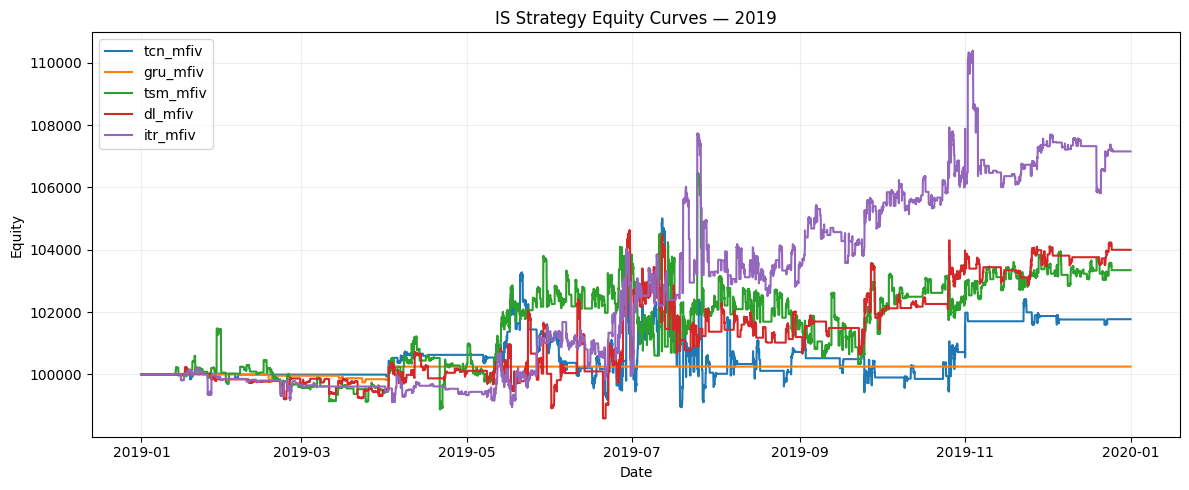

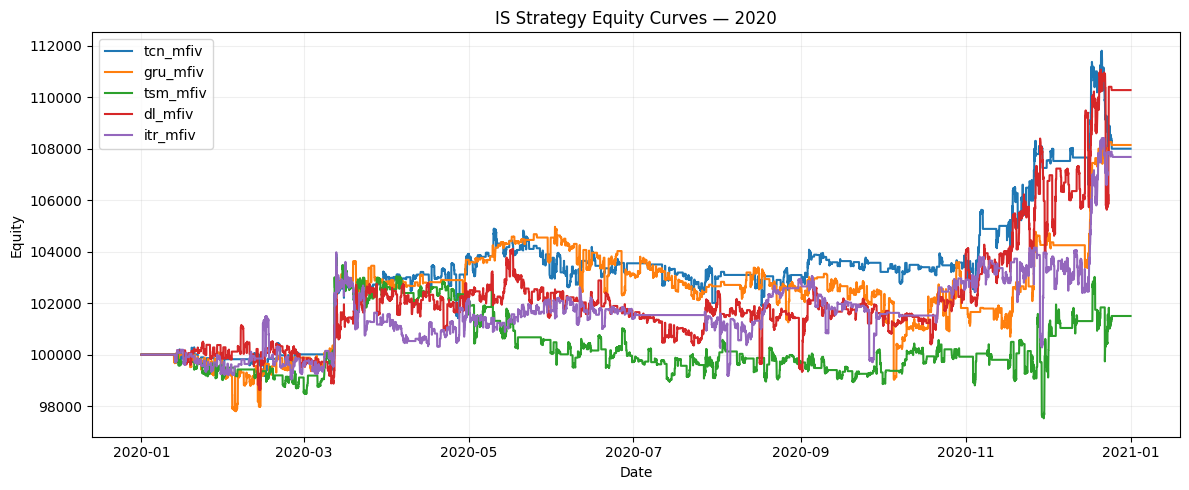

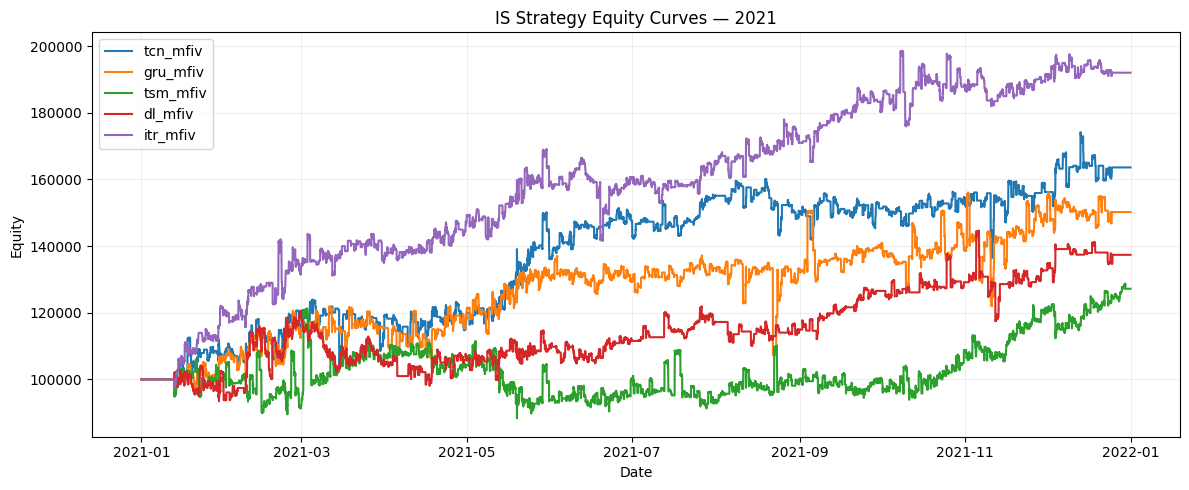

In [ ]:
import matplotlib.pyplot as plt

MODELS = [
    "tcn_mfiv",
    "gru_mfiv",
    "tsm_mfiv",
    "dl_mfiv",
    "itr_mfiv"
]

YEARS = [2019, 2020, 2021]

for y in YEARS:

    plt.figure(figsize=(12, 5))

    for MODEL in MODELS:

        history_key = f"{MODEL}_{str(y)[2:]}"
        snapshots = strategy_results[history_key]["snapshots"]

        equity = pd.Series(
            [s["equity"] for s in snapshots],
            index=[s["time"] for s in snapshots]
        )

        plt.plot(equity.index, equity.values, label=MODEL)

    plt.title(f"IS Strategy Equity Curves — {y}")
    plt.xlabel("Date")
    plt.ylabel("Equity")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

dict_keys(['tcn_mfiv_22', 'gru_mfiv_22', 'tsm_mfiv_22', 'dl_mfiv_22', 'itr_mfiv_22'])


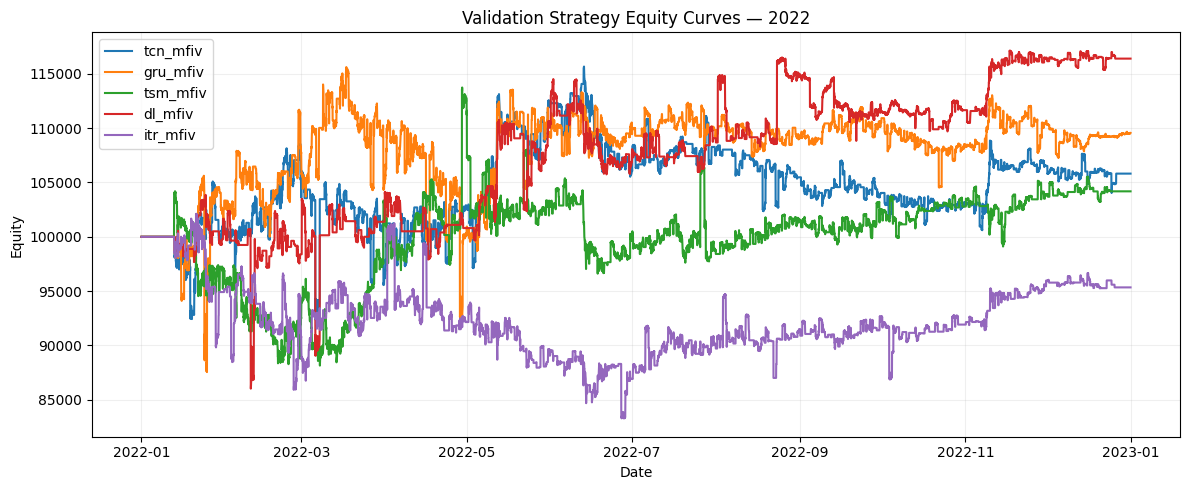

In [ ]:
with open(
    "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/VAL/strategy_results_2022.pkl",
    "rb"
) as f:
    strategy_results_VAL = pickle.load(f)

print(strategy_results_VAL.keys())


# =============================================================================================================
# ======================================= PLOT VALIDATION EQUITY CURVES =======================================
# =============================================================================================================

MODELS = [
    "tcn_mfiv",
    "gru_mfiv",
    "tsm_mfiv",
    "dl_mfiv",
    "itr_mfiv"
]

VALIDATION_YEAR = 2022

plt.figure(figsize=(12, 5))

for MODEL in MODELS:

    history_key = f"{MODEL}_{str(VALIDATION_YEAR)[2:]}"
    snapshots = strategy_results_VAL[history_key]["snapshots"]

    equity = pd.Series(
        [s["equity"] for s in snapshots],
        index=[s["time"] for s in snapshots]
    )

    plt.plot(
        equity.index,
        equity.values,
        label=MODEL
    )

plt.title(f"Validation Strategy Equity Curves — {VALIDATION_YEAR}")
plt.xlabel("Date")
plt.ylabel("Equity")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()